
===== DATASET IRIS =====
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   
5                5.4               3.9                1.7               0.4   
6                4.6               3.4                1.4               0.3   
7                5.0               3.4                1.5               0.2   
8                4.4               2.9                1.4               0.2   
9                4.9               3.1                1.5               0.1   

  Especie  
0  setosa  
1  setosa  
2  setosa  
3  setosa  
4  setosa  
5  setosa  
6  setosa  
7  setos

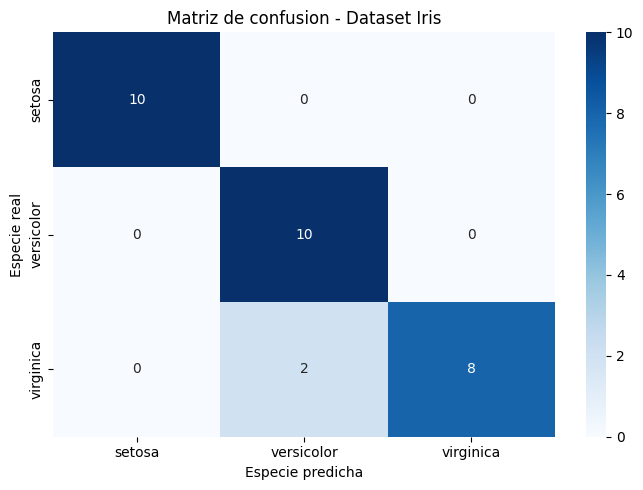

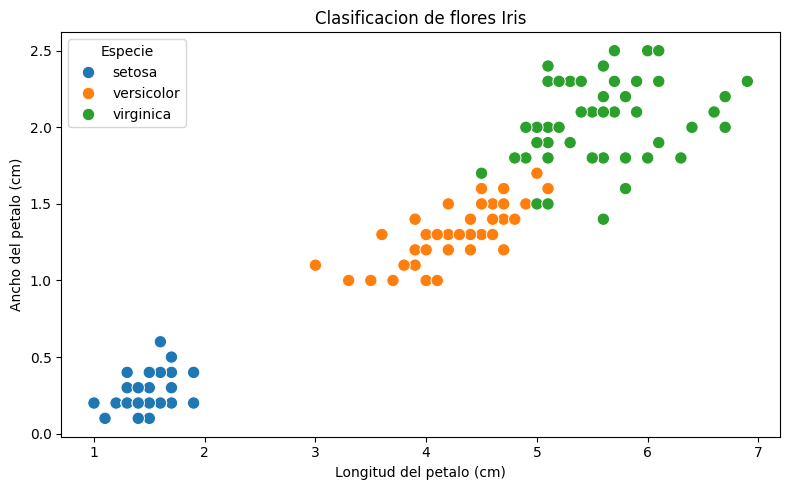


===== PREDICCION DE FLOR NUEVA =====
Especie identificada: setosa

===== PROGRAMA FINALIZADO =====

       PREDICCION INTERACTIVA

Introduce las medidas de tu flor en centimetros.


In [ ]:
# 1. IMPORTAR LIBRERIAS
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report


# 2. CARGAR EL DATASET IRIS
#biblioteca Scikit-learn.

iris = load_iris()

# Guardamos las caracteristicas en X
X = iris.data

# Guardamos las especies en Y
y = iris.target

# Creamos un DataFrame para visualizar los datos
df = pd.DataFrame(
    X,
    columns=iris.feature_names
)

# Agregamos la columna de las especies
df["Especie"] = [
    iris.target_names[i] for i in y
]

print("\n===== DATASET IRIS =====")
print(df.head(10))


# 3. INFORMACION GENERAL DEL DATASET
print("\n===== INFORMACION DEL DATASET =====")

print("Cantidad de registros:", len(df))
print("Cantidad de caracteristicas:", X.shape[1])

print("\nCantidad por especie:")
print(df["Especie"].value_counts())

# 4. DIVIDIR LOS DATOS
# 80% de los datos para entrenamiento
# 20% de los datos para pruebas

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\n===== DIVISION DE DATOS =====")

print("Datos de entrenamiento:", len(X_train))
print("Datos de prueba:", len(X_test))

# 5. NORMALIZAR LOS DATOS
# Ajustamos la escala utilizando solamente
# los datos de entrenamiento.
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)


# 6. CREAR Y ENTRENAR EL MODELO KNN
# Utilizamos 5 vecinos cercanos.

modelo = KNeighborsClassifier(n_neighbors=5)

# Entrenamos el modelo con los datos disponibles.

modelo.fit(X_train, y_train)

print("\n===== MODELO ENTRENADO =====")
print("El algoritmo KNN ha sido entrenado correctamente.")

# 7. REALIZAR PREDICCIONES

# El modelo realiza predicciones con los datos
# que no utilizo durante el entrenamiento.

predicciones = modelo.predict(X_test)

print("\n===== PREDICCIONES =====")

for i in range(len(predicciones)):
    real = iris.target_names[y_test[i]]
    predicho = iris.target_names[predicciones[i]]

    print("Real:", real, "| Prediccion:", predicho)

# 8. EVALUAR EL MODELO

precision = accuracy_score(y_test, predicciones)

print("\n===== EVALUACION DEL MODELO =====")

print("Precision:", round(precision * 100, 2), "%")

print("\nReporte de clasificacion:")

print(classification_report(
    y_test,
    predicciones,
    target_names=iris.target_names
))


# 9. MATRIZ DE CONFUSION

matriz = confusion_matrix(y_test, predicciones)

plt.figure(figsize=(7, 5))

sns.heatmap(
    matriz,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.title("Matriz de confusion - Dataset Iris")
plt.xlabel("Especie predicha")
plt.ylabel("Especie real")

plt.tight_layout()
plt.show()


# 10. GRAFICA DE LOS DATOS


plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="petal length (cm)",
    y="petal width (cm)",
    hue="Especie",
    s=80
)

plt.title("Clasificacion de flores Iris")
plt.xlabel("Longitud del petalo (cm)")
plt.ylabel("Ancho del petalo (cm)")

plt.tight_layout()
plt.show()


# 11. PREDECIR UNA FLOR NUEVA
# Caracteristicas de una flor nueva:
# [largo sepalo, ancho sepalo,
#  largo petalo, ancho petalo]

flor_nueva = np.array([[5.1, 3.5, 1.4, 0.2]])

# Normalizamos los datos nuevos
flor_nueva = scaler.transform(flor_nueva)

# Realizamos la prediccion
resultado = modelo.predict(flor_nueva)

# Convertimos el resultado numerico
# al nombre de la especie.

especie = iris.target_names[resultado[0]]

print("\n===== PREDICCION DE FLOR NUEVA =====")

print("Especie identificada:", especie)

print("\n===== PROGRAMA FINALIZADO =====")


# 12. SECCION INTERACTIVA PARA EL USUARIO

print("\n====================================")
print("       PREDICCION INTERACTIVA")
print("====================================")

print("\nIntroduce las medidas de tu flor en centimetros.")

try:
    # Solicitar las 4 caracteristicas de la flor

    largo_sepalo = float(input(
        "\nLongitud del sepalo (cm): "
    ))

    ancho_sepalo = float(input(
        "Ancho del sepalo (cm): "
    ))

    largo_petalo = float(input(
        "Longitud del petalo (cm): "
    ))

    ancho_petalo = float(input(
        "Ancho del petalo (cm): "
    ))

    # Guardar las medidas en un arreglo
    datos_usuario = np.array([[
        largo_sepalo,
        ancho_sepalo,
        largo_petalo,
        ancho_petalo
    ]])

    # Validar que las medidas sean positivas
    if np.any(datos_usuario <= 0):
        print("\nError: Las medidas deben ser mayores que cero.")

    else:
        # Normalizar los datos introducidos
        datos_normalizados = scaler.transform(datos_usuario)

        # Realizar la prediccion
        prediccion = modelo.predict(datos_normalizados)

        # Obtener el nombre de la especie
        especie_predicha = iris.target_names[prediccion[0]]

        # Mostrar resultados
        print("\n====================================")
        print("          RESULTADO")
        print("====================================")

        print("\nMedidas introducidas:")
        print("Longitud del sepalo:", largo_sepalo, "cm")
        print("Ancho del sepalo:", ancho_sepalo, "cm")
        print("Longitud del petalo:", largo_petalo, "cm")
        print("Ancho del petalo:", ancho_petalo, "cm")

        print("\nLa especie identificada es:")
        print(">>>", especie_predicha.upper(), "<<<")

        print("\nPrediccion realizada correctamente.")

except ValueError:
    print("\nError: Debes introducir valores numericos.")

print("\n====================================")
print("       FIN DEL PROGRAMA")
print("====================================")
